
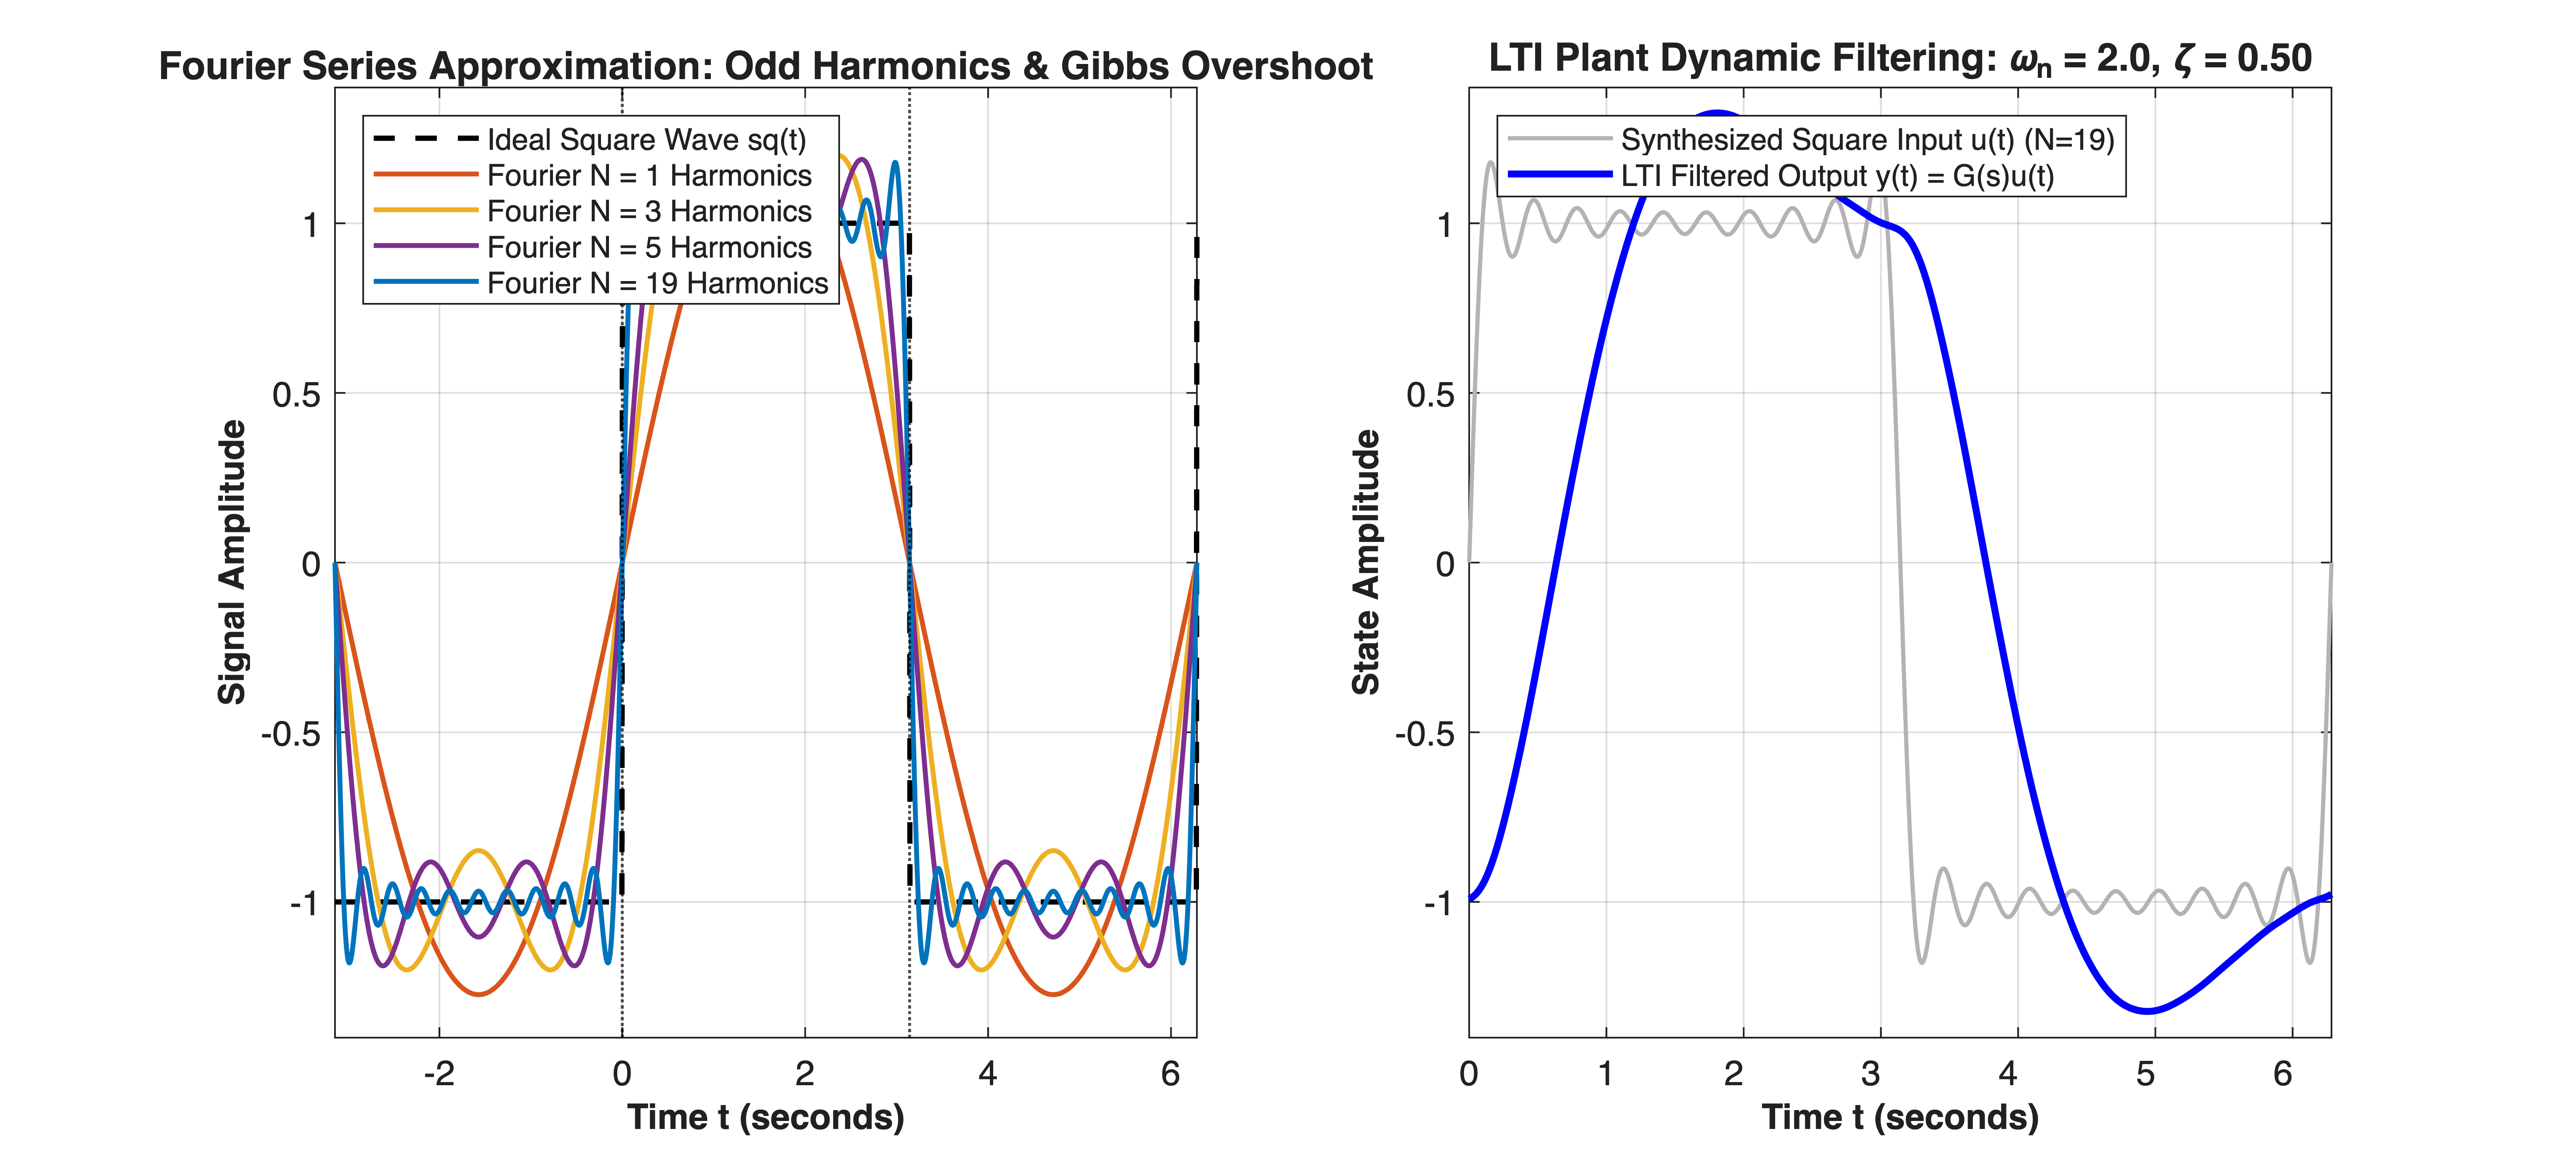

In [1]:
%% MIT 18.03 Lecture 20: Periodic Signals, Fourier Series & LTI Filtering
% Description: Simulates Fourier series expansion and LTI plant harmonic response:
%              1) Synthesizes Fourier series of square wave: sq(t) = (4/pi)*sum(sin(n*t)/n) for odd n.
%              2) Demonstrates harmonic convergence and Gibbs phenomenon overshoot at discontinuities.
%              3) Feeds synthesized periodic input into a 2nd-order LTI plant via Control System Toolbox 'lsim'.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, lsim, bode).
%
% % MBD Concept Mapping: Demonstrates periodic signal decomposition into orthogonal harmonics.
% %                      Validates LTI harmonic synthesis: y_ss(t) = sum |G(j*n*w0)|*u_n(t - delay),
% %                      showing high-frequency harmonic attenuation by low-pass physical plants.


clear; clc; close all;


%% =========================================================================
%% Part 1: Fourier Series Synthesis of Standard Square Wave (Section [2])
%% =========================================================================
% Fundamental frequency w0 = 1 rad/s, Period T0 = 2*pi, L = pi
t_span = [-pi, 2 * pi];
t_grid = linspace(t_span(1), t_span(2), 1500);


% Ideal square wave: +1 on (0, pi), -1 on (-pi, 0)
sq_ideal = square(t_grid);


% Odd harmonic truncation sets
harmonic_limits = [1, 3, 5, 19];
sq_approx = zeros(length(harmonic_limits), length(t_grid));


for idx = 1:length(harmonic_limits)
    N_max = harmonic_limits(idx);
    sum_wave = zeros(size(t_grid));
    for n = 1:2:N_max
        bn = 4 / (n * pi); % Fourier sine coefficient for odd n
        sum_wave = sum_wave + bn * sin(n * t_grid);
    end
    sq_approx(idx, :) = sum_wave;
end


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 520]);


% Subplot 1: Fourier Truncation Convergence & Gibbs Phenomenon
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_grid, sq_ideal, 'k--', 'LineWidth', 1.5, 'DisplayName', 'Ideal Square Wave sq(t)');
colors = [0.85 0.33 0.10; 0.93 0.69 0.13; 0.49 0.18 0.56; 0.00 0.45 0.74];


for idx = 1:length(harmonic_limits)
    plot(t_grid, sq_approx(idx, :), 'Color', colors(idx, :), 'LineWidth', 1.4, ...
        'DisplayName', sprintf('Fourier N = %d Harmonics', harmonic_limits(idx)));
end


xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xline(pi, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Signal Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('Fourier Series Approximation: Odd Harmonics & Gibbs Overshoot', ...
    'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([t_span(1), t_span(2)]);
ylim([-1.4, 1.4]);


%% =========================================================================
%% Part 2: LTI Plant Filtering Response via Control System Toolbox
%% =========================================================================
% Define 2nd-order mechanical/electrical plant: G(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
wn = 2.0;       % Natural frequency (rad/s)
zeta = 0.5;     % Underdamped damping ratio
G_plant = tf(wn^2, [1, 2*zeta*wn, wn^2]);


% Simulate response to Fourier-synthesized periodic input (N = 19)
u_input = sq_approx(end, :);
[y_plant_response, ~] = lsim(G_plant, u_input, t_grid);


% Subplot 2: Dynamic Harmonic Smoothing by LTI Physical Plant
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_grid, u_input, 'Color', [0.7 0.7 0.7], 'LineWidth', 1.2, ...
    'DisplayName', 'Synthesized Square Input u(t) (N=19)');
plot(t_grid, y_plant_response, 'b-', 'LineWidth', 2.0, ...
    'DisplayName', 'LTI Filtered Output y(t) = G(s)u(t)');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('LTI Plant Dynamic Filtering: \\omega_n = %.1f, \\zeta = %.2f', wn, zeta), ...
    'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8.5);
xlim([0, 2 * pi]);
ylim([-1.4, 1.4]);

In [2]:


fprintf('=== MIT 18.03 Lecture 20 Diagnostics ===\n');

=== MIT 18.03 Lecture 20 Diagnostics ===

In [3]:
fprintf('Fundamental Period T0 : 2*pi = %.4f s\n', 2*pi);

Fundamental Period T0 : 2*pi = 6.2832 s

In [4]:
fprintf('Square Wave Expansion : sq(t) = sum_{odd n} (4/(n*pi)) * sin(n*t)\n');

Square Wave Expansion : sq(t) = sum_{odd n} (4/(n*pi)) * sin(n*t)

In [5]:
fprintf('First 3 Coefficients  : b1 = %.4f, b3 = %.4f, b5 = %.4f\n', ...
    4/pi, 4/(3*pi), 4/(5*pi));

First 3 Coefficients  : b1 = 1.2732, b3 = 0.4244, b5 = 0.2546

In [6]:
fprintf('Plant Transfer Function:\n');

Plant Transfer Function:

In [7]:
display(G_plant);

G_plant =
 
        4
  -------------
  s^2 + 2 s + 4
 
Continuous-time transfer function.
Model Properties

In [8]:
fprintf('========================================\n');